In [137]:
from datetime import timedelta
from joblib import load
from socceraction.atomic.vaep.formula import value
from statsbombpy import sb
from tqdm import tqdm
import duckdb
import matplotlib.pyplot as plt
import os
import pandas as pd
import seaborn as sns
import socceraction.atomic.spadl as atomicspadl
import numpy as np

In [2]:
actions_data = []

for actions_file in os.listdir("../data/actions"):
    actions_data.append(
        pd.read_parquet(
            f"../data/actions/{actions_file}",
            engine="fastparquet"
        )
    )

actions_df = atomicspadl.add_names(pd.concat(actions_data))

In [3]:
events_data = []

for events_file in os.listdir("../data/events"):
    events_data.append(
        pd.read_parquet(
            f"../data/events/{events_file}",
            engine="fastparquet"
        )
    )

events_df = pd.concat(events_data)

In [4]:
max_match_mins_df = events_df[events_df["period"] != 5][["match_id", "minute"]].groupby("match_id").agg({"minute": "max"}).reset_index()

In [5]:
players = {}

for match_id in tqdm(max_match_mins_df["match_id"].tolist(), desc="Processing Matches"):

    for data in sb.lineups(match_id=match_id).values():
        
        for player_id, position_data in zip(data.get("player_id").tolist(), data.get("positions").tolist()):

            if len(position_data) == 0:
                start_time = timedelta(seconds=0)
                end_time = timedelta(seconds=0)

            if len(position_data) != 0:
                start_minutes, start_seconds = map(int, position_data[0].get("from").split(":"))
                start_time = timedelta(minutes=start_minutes, seconds=start_seconds)

            if len(position_data) == 1:

                if not position_data[0].get("to"):
                    end_time = timedelta(minutes=max_match_mins_df[max_match_mins_df["match_id"] == match_id]["minute"].item())
                else:
                    end_minutes, end_seconds = map(int, position_data[0].get("to").split(":"))
                    end_time = timedelta(minutes=end_minutes, seconds=end_seconds)
            
            if len(position_data) > 1:
                if not position_data[-1].get("to"):
                    end_time = timedelta(minutes=max_match_mins_df[max_match_mins_df["match_id"] == match_id]["minute"].item())
                else:
                    end_minutes, end_seconds = map(int, position_data[-1].get("to").split(":"))
                    end_time = timedelta(minutes=end_minutes, seconds=end_seconds)

            if player_id not in players:
                players[player_id] = timedelta(seconds=0)
            
            time_played = end_time - start_time
            players[player_id] += time_played

Processing Matches:   0%|          | 0/292 [00:00<?, ?it/s]c:\Users\Charlie\Documents\coding\python\projects\dissertation\.venv\Lib\site-packages\statsbombpy\api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
Processing Matches: 100%|██████████| 292/292 [02:32<00:00,  1.91it/s]


In [6]:
X_train = load("../data/modelling/train/X_train_dict.pkl")
X_test = load("../data/modelling/test/X_test_dict.pkl")
y_train = load("../data/modelling/train/targets_train_dict.pkl")
y_test = load("../data/modelling/test/targets_test_dict.pkl")

In [7]:
id_cols = ["game_id", "action_id"]

manual_spatial_feature_prefixes = [
    "actor_minimum_distance_to_opponent",
    "actor_minimum_distance_to_teammate",
    "actor_mean_distance_to_opponent",
    "actor_mean_distance_to_teammate",
    "actor_stdev_distance_to_opponent",
    "actor_stdev_distance_to_teammate",
    "number_of_opponents_within_radius_of_actor",
    "number_of_teammates_within_radius_of_actor",
    "opponent_convex_hull_area",
    "teammate_convex_hull_area",
]

manual_spatial_feature_cols = [
    c for c in X_train["all"].columns
    if any(c.startswith(prefix) for prefix in manual_spatial_feature_prefixes)
]

spatial_embedding_feature_cols = [
    c for c in X_train["all"].columns
    if c.startswith("spatial_embedding_")
]

baseline_feature_cols = [
    c for c in X_train["all"].columns
    if (
        c not in manual_spatial_feature_cols
        and c not in spatial_embedding_feature_cols
    )
]

In [8]:
atomic_actions_all_df = pd.concat([X_train["all"], X_test["all"]])
atomic_actions_all_df["concedes"] = pd.concat([y_train["concedes"], y_test["concedes"]])
atomic_actions_all_df["scores"] = pd.concat([y_train["scores"], y_test["scores"]])

del X_train, X_test, y_train, y_test

<positron-console-cell-8>:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-8>:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


In [9]:
concedes_classifier_model = load("../models/classifiers/xgboost_baseline_concedes.pkl")
scores_classifier_model = load("../models/classifiers/xgboost_all_scores.pkl")

In [15]:
preds_df = atomic_actions_all_df[["game_id", "action_id"]].reset_index(drop=True)

preds_df["pconcedes"] = concedes_classifier_model.predict_proba(
    atomic_actions_all_df[baseline_feature_cols].drop(["game_id", "action_id"], axis=1)
)[:, 1]

preds_df["pscores"] = scores_classifier_model.predict_proba(
    atomic_actions_all_df.drop(["game_id", "action_id", "concedes", "scores"], axis=1)
)[:, 1]

actions_df = actions_df.merge(preds_df, on=["game_id", "action_id"], how="left")

In [16]:
actions_df[["offensive_value", "defensive_value", "vaep_value"]] = value(
    actions_df,
    actions_df["pscores"], 
    actions_df["pconcedes"]
)

In [17]:
mins_played_df = pd.DataFrame({k: v.total_seconds() / 60 for k, v in players.items()}.items(), columns=["player_id", "minutes_played"])

In [18]:
mins_played_df = mins_played_df[mins_played_df["minutes_played"] > 0]

In [19]:
total_vaep_value_df = actions_df[["player_id", "vaep_value"]].groupby("player_id").agg(vaep_value=("vaep_value", "sum"), number_of_actions=("player_id", "size")).reset_index()

In [20]:
players_mins_and_vaep_df = pd.merge(
    mins_played_df,
    total_vaep_value_df,
    on="player_id",
    how="left"
)

In [21]:
players_mins_and_vaep_df["90s_played"] = players_mins_and_vaep_df["minutes_played"] / 90

In [22]:
players_mins_and_vaep_df["actions_per_90"] = players_mins_and_vaep_df["number_of_actions"] / players_mins_and_vaep_df["90s_played"]
players_mins_and_vaep_df["vaep_per_90"] = players_mins_and_vaep_df["vaep_value"] / players_mins_and_vaep_df["90s_played"]

In [23]:
players_mins_and_vaep_df["vaep_per_action"] = players_mins_and_vaep_df["vaep_value"] / players_mins_and_vaep_df["number_of_actions"]

In [24]:
vaep_player_data_df = pd.merge(
    players_mins_and_vaep_df,
    events_df[["player_id", "player", "position"]],
    on="player_id",
    how="left"
).drop_duplicates().dropna()

In [25]:
vaep_player_data_with_competition_df = pd.merge(
    vaep_player_data_df,
    events_df[["player_id", "competition"]],
    on="player_id",
    how="left"
).drop_duplicates()

In [26]:
vaep_player_data_with_competition_df["player_gender"] = vaep_player_data_with_competition_df["competition"].str.contains("Women's", case=False, na=False).map({True: "female", False: "male"})
vaep_player_data_with_competition_df = vaep_player_data_with_competition_df[vaep_player_data_with_competition_df["position"] != "Goalkeeper"]
vaep_player_data_with_competition_df = vaep_player_data_with_competition_df.drop(columns=["position"], axis=1).drop_duplicates()

In [27]:
vaep_to_actions_plot_df = vaep_player_data_with_competition_df[
    vaep_player_data_with_competition_df["90s_played"] > 3
][["player", "player_gender", "90s_played", "actions_per_90", "vaep_per_action"]].drop_duplicates()

vaep_to_actions_plot_df = vaep_to_actions_plot_df.reset_index(drop=True)

<positron-console-cell-28>:46: UserWarning: The figure layout has changed to tight


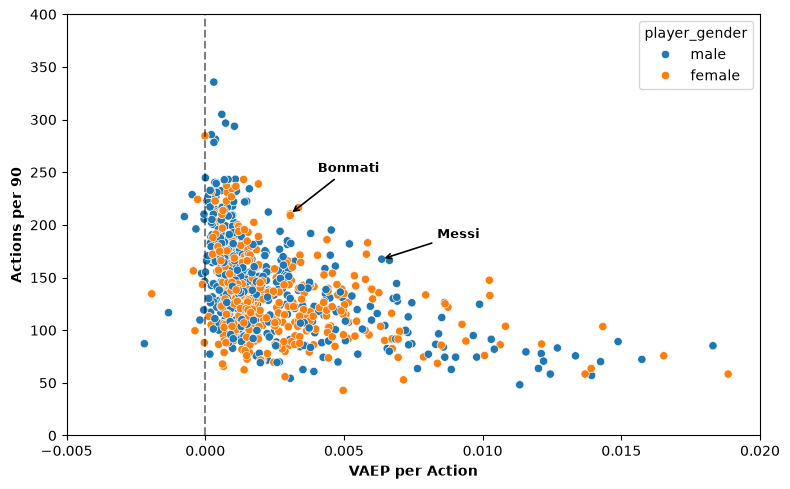

In [28]:
plt.figure(figsize=(8,5), constrained_layout=True)

sns.scatterplot(
    data=vaep_to_actions_plot_df,
    x="vaep_per_action",
    y="actions_per_90",
    hue="player_gender"
)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.5)

plt.xlim(-0.005, 0.02)
plt.xlabel("VAEP per Action", fontweight="bold")

plt.ylim(0, 400)
plt.ylabel("Actions per 90", fontweight="bold")

messi_row = vaep_to_actions_plot_df[
    vaep_to_actions_plot_df["player"] == "Lionel Andrés Messi Cuccittini"
]

messi_row = messi_row.iloc[0]
plt.annotate(
    "Messi",
    xy=(messi_row["vaep_per_action"], messi_row["actions_per_90"]),
    xytext=(messi_row["vaep_per_action"] + 0.002, messi_row["actions_per_90"] + 20),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9,
    fontweight="bold"
)

bonmati_row = vaep_to_actions_plot_df[
    vaep_to_actions_plot_df["player"] == "Aitana Bonmati Conca"
]

bonmati_row = bonmati_row.iloc[0]
plt.annotate(
    "Bonmati",
    xy=(bonmati_row["vaep_per_action"], bonmati_row["actions_per_90"]),
    xytext=(bonmati_row["vaep_per_action"] + 0.001, bonmati_row["actions_per_90"] + 40),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/vaep_per_action_actions_per_90.png", dpi=300)
plt.show()

In [123]:
player_ratings_df = (
    vaep_player_data_with_competition_df.groupby(["player_id", "player", "player_gender"], as_index=False)
      .agg(
          minutes_played=("minutes_played", "first"),
          total_vaep=("vaep_value", "first")
      )
)

player_ratings_df["rating"] = (
    90 * player_ratings_df["total_vaep"] /
    player_ratings_df["minutes_played"]
)

player_ratings_df = player_ratings_df[
    ["player_id", "player", "player_gender",  "minutes_played", "rating"]
].sort_values("rating", ascending=False)

conn = duckdb.connect("../data/reep-register-v1.duckdb")

statsbomb_id_to_transfermarkt_id_mapping_df = conn.sql("""
SELECT
    sb.external_id AS statsbomb_player_id,
    tm.external_id AS transfermarkt_player_id,
    p.label AS player
FROM bridges sb
JOIN bridges tm
    ON sb.reep_id = tm.reep_id
JOIN players p
    ON p.reep_id = sb.reep_id
WHERE sb.provider = 'statsbomb'
  AND tm.provider = 'transfermarkt';
""").df()

conn.close()

statsbomb_id_to_transfermarkt_id_mapping_df["statsbomb_player_id"] = statsbomb_id_to_transfermarkt_id_mapping_df["statsbomb_player_id"].astype(int)
statsbomb_id_to_transfermarkt_id_mapping_df["transfermarkt_player_id"] = statsbomb_id_to_transfermarkt_id_mapping_df["transfermarkt_player_id"].astype(int)

player_ratings_df = player_ratings_df.merge(
    statsbomb_id_to_transfermarkt_id_mapping_df.drop("player", axis=1),
    left_on="player_id",
    right_on="statsbomb_player_id",
    how="left"
)

transfermarkt_player_values_df = pd.read_csv("../data/player_valuations.csv", usecols=["date", "player_id", "market_value_in_eur"])

transfermarkt_player_values_df["date"] = pd.to_datetime(transfermarkt_player_values_df["date"], format="mixed")

transfermarkt_player_values_df = transfermarkt_player_values_df[transfermarkt_player_values_df["date"] > "2025-08-01"]

player_ratings_df = pd.merge(
    player_ratings_df,
    transfermarkt_player_values_df,
    left_on="transfermarkt_player_id",
    right_on="player_id",
    how="left"
).sort_values("date", ascending=True).drop(["player_id_y", "date"], axis=1).drop_duplicates(subset="player_id_x", keep="last")

player_ratings_df.drop("statsbomb_player_id", inplace=True, axis=1)

player_ratings_sufficient_playtime_df = player_ratings_df[player_ratings_df["minutes_played"] >= 270]

player_ratings_male_df = player_ratings_sufficient_playtime_df[player_ratings_sufficient_playtime_df["player_gender"] == "male"]
player_ratings_female_df = player_ratings_sufficient_playtime_df[player_ratings_sufficient_playtime_df["player_gender"] == "female"]

In [230]:
(
    player_ratings_male_df[["player", "minutes_played", "rating"]]
    .sort_values("rating", ascending=False)
    .head(10)
    .to_parquet(
        "../results/top10_vaep_player_ratings_male.parquet", 
        compression="zstd", 
        index=False
    )
)

In [231]:
(
    player_ratings_female_df[["player", "minutes_played", "rating"]]
    .sort_values("rating", ascending=False)
    .head(10)
    .to_parquet(
        "../results/top10_vaep_player_ratings_female.parquet", 
        compression="zstd", 
        index=False
    )
)

In [138]:
from scipy.stats import spearmanr
from scipy.stats import linregress

player_rating_market_value_corr_df = player_ratings_male_df.dropna()

rho, p = spearmanr(
    player_rating_market_value_corr_df["rating"],
    player_rating_market_value_corr_df["market_value_in_eur"]
)

print(f"rho: {rho}, p: {p}")

rho: 0.12672244278928207, p: 0.01069049602913187


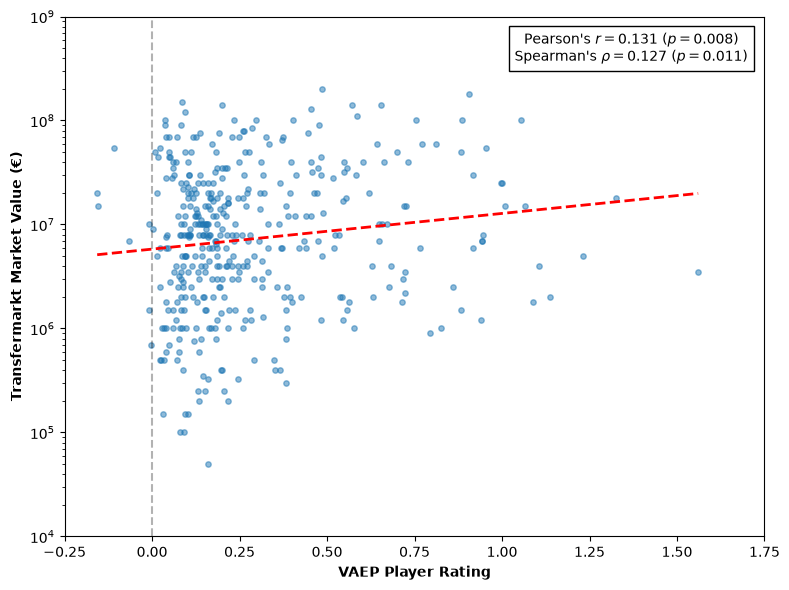

In [226]:
x = player_rating_market_value_corr_df["rating"]
y = np.log10(player_rating_market_value_corr_df["market_value_in_eur"])

slope, intercept, r, p_pearson, stderr = linregress(x, y)

plt.figure(figsize=(8,6))

plt.scatter(
    x,
    player_rating_market_value_corr_df["market_value_in_eur"],
    alpha=0.5,
    s=15
)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = 10 ** (intercept + slope * x_line)

plt.plot(x_line, y_line, linewidth=2, linestyle="--", color="red")

rho, p_spearman = spearmanr(
    player_rating_market_value_corr_df["rating"],
    player_rating_market_value_corr_df["market_value_in_eur"]
)

plt.text(
    0.81, 0.905,
    f"Pearson's " + rf"$r = {r:.3f}$ " + rf"$\left(p = {p_pearson:.3f}\right)$" + "\n" + f"Spearman's " + rf"$\rho = {rho:.3f}$ " + rf"$\left(p = {p_spearman:.3f}\right)$",
    transform=plt.gca().transAxes,
    ha="center",
    va="bottom",
    bbox=dict(facecolor="white", alpha=1)
)

plt.xlim(-0.25, 1.75)

plt.yscale("log")
plt.ylim(1e4, 1e9)

plt.axvline(x=0, color="black", linestyle="--", alpha=0.3)

plt.xlabel("VAEP Player Rating", fontweight="bold")
plt.ylabel("Transfermarkt Market Value (€)", fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/dissertation/figures/vaep_rating_market_value_scatterplot.png", dpi=300)
plt.show()